First five rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area 

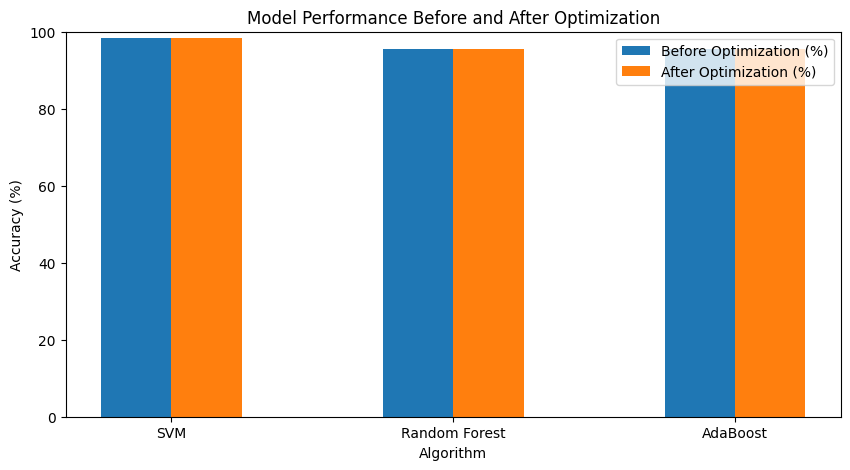

In [3]:

# PR11: Advanced Machine Learning and Model Optimization

# * TASK 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, classification_report


# * TASK 2: Load Breast Cancer dataset
data = load_breast_cancer()

df = pd.DataFrame(data.data, columns=data.feature_names)
df["Target"] = data.target

print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)


# * TASK 3: Separate features and target
X = df.drop("Target", axis=1)
y = df["Target"]

print("\nFeatures:")
print(X.head())

print("\nTarget:")
print(y.head())


# * TASK 4: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# * TASK 5: Create machine learning models
models = {
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC())
    ]),
    "Random Forest": RandomForestClassifier(
        random_state=42
    ),
    "AdaBoost": AdaBoostClassifier(
        random_state=42
    )
}


# * TASK 6: Train and compare models
results = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    results[name] = accuracy

    print("\n", name)
    print("Accuracy:", round(accuracy * 100, 2), "%")
    print(classification_report(y_test, y_pred))


# * TASK 7: Perform Cross Validation
print("\nCross Validation Results:")

for name, model in models.items():
    scores = cross_val_score(
        model, X_train, y_train, cv=5, scoring="accuracy"
    )

    print(name, "CV Accuracy:",
          round(scores.mean() * 100, 2), "%")


# * TASK 8: Hyperparameter Tuning using Grid Search

# SVM Grid Search
svm_grid = GridSearchCV(
    Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC())
    ]),
    {
        "model__C": [0.1, 1, 10],
        "model__kernel": ["linear", "rbf"]
    },
    cv=5,
    scoring="accuracy"
)

svm_grid.fit(X_train, y_train)

print("\nBest SVM Parameters:", svm_grid.best_params_)
print("Best SVM Score:", round(svm_grid.best_score_ * 100, 2), "%")


# Random Forest Grid Search
rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    {
        "n_estimators": [50, 100],
        "max_depth": [None, 5, 10]
    },
    cv=5,
    scoring="accuracy"
)

rf_grid.fit(X_train, y_train)

print("\nBest Random Forest Parameters:", rf_grid.best_params_)
print("Best Random Forest Score:",
      round(rf_grid.best_score_ * 100, 2), "%")


# AdaBoost Grid Search
ada_grid = GridSearchCV(
    AdaBoostClassifier(random_state=42),
    {
        "n_estimators": [50, 100],
        "learning_rate": [0.5, 1.0]
    },
    cv=5,
    scoring="accuracy"
)

ada_grid.fit(X_train, y_train)

print("\nBest AdaBoost Parameters:", ada_grid.best_params_)
print("Best AdaBoost Score:",
      round(ada_grid.best_score_ * 100, 2), "%")


# * TASK 9: Compare model accuracy
best_models = {
    "SVM": svm_grid.best_estimator_,
    "Random Forest": rf_grid.best_estimator_,
    "AdaBoost": ada_grid.best_estimator_
}

tuned_results = {}

for name, model in best_models.items():
    y_pred = model.predict(X_test)
    tuned_results[name] = accuracy_score(y_test, y_pred)

    print(name, "Tuned Accuracy:",
          round(tuned_results[name] * 100, 2), "%")


# * TASK 10: Compare model performance before and after optimization

algorithms = ["SVM", "Random Forest", "AdaBoost"]

before = [results[name] * 100 for name in algorithms]
after = [tuned_results[name] * 100 for name in algorithms]

import numpy as np

x = np.arange(len(algorithms))
width = 0.25

plt.figure(figsize=(10, 5))

plt.bar(
    x - width/2,
    before,
    width,
    label="Before Optimization (%)"
)

plt.bar(
    x + width/2,
    after,
    width,
    label="After Optimization (%)"
)

plt.xlabel("Algorithm")
plt.ylabel("Accuracy (%)")
plt.title("Model Performance Before and After Optimization")

plt.xticks(x, algorithms)
plt.ylim(0, 100)
plt.legend()

plt.show()

